# BiLSTM Sentiment Classification and Evaluation

This notebook trains a binary sentiment classifier using the sequences produced in notebook 02. Token IDs pass through a trainable embedding, a bidirectional LSTM, and a sigmoid output layer. Labels are `0` for negative sentiment and `1` for positive sentiment. Training uses the training split, checkpoint selection uses the validation split, and final performance is measured on the held-out test split.

## Computational environment

The notebooks were run with a shared Python 3.11 environment containing the packages in `requirements.txt`. This environment provides TensorFlow for the BiLSTM and a consistent kernel across the exploration, preprocessing, and modelling notebooks.

In [10]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

SEED = 42
tf.keras.utils.set_random_seed(SEED)
PREPARED_DIR = Path("data/prepared")
MODEL_DIR = Path("models")

## 1. Prepared data

The numerical sequences, labels, vocabulary, and metadata from notebook 02 are loaded here. Shape, token-range, and label checks confirm that the saved arrays match the model inputs. The training, validation, and test splits contain 1,233,032, 154,128, and 154,131 examples, respectively.

In [11]:
required = [PREPARED_DIR / f"{kind}_{name}.npy" for name in ("train", "validation", "test") for kind in ("X", "y")]
required += [PREPARED_DIR / "vocab.json", PREPARED_DIR / "metadata.json"]
missing = [str(path) for path in required if not path.exists()]
if missing:
    raise FileNotFoundError(f"Run notebook 02's save cell first. Missing: {missing}")

X = {name: np.load(PREPARED_DIR / f"X_{name}.npy") for name in ("train", "validation", "test")}
y = {name: np.load(PREPARED_DIR / f"y_{name}.npy") for name in X}
with (PREPARED_DIR / "metadata.json").open(encoding="utf-8") as file:
    metadata = json.load(file)
with (PREPARED_DIR / "vocab.json").open(encoding="utf-8") as file:
    vocab = json.load(file)
MAX_LENGTH = metadata["max_length"]
VOCAB_SIZE = metadata["vocab_size"]
assert len(vocab) == VOCAB_SIZE and vocab["<pad>"] == 0 and vocab["<unk>"] == 1
for name in X:
    assert X[name].ndim == 2 and X[name].shape[1] == MAX_LENGTH
    assert len(X[name]) == len(y[name])
    assert X[name].min() >= 0 and X[name].max() < VOCAB_SIZE
    assert set(np.unique(y[name])).issubset({0, 1})
    print(f"{name}: {len(y[name]):,} rows, positive rate {y[name].mean() * 100:.2f}%")
print(f"Vocabulary: {VOCAB_SIZE:,}; sequence length: {MAX_LENGTH}")

train: 1,233,032 rows, positive rate 49.76%
validation: 154,128 rows, positive rate 49.76%
test: 154,131 rows, positive rate 49.76%
Vocabulary: 40,000; sequence length: 31


## 2. Model architecture

A 128-dimensional embedding learns token representations from training data. Padding ID `0` is masked so padded positions do not contribute to the BiLSTM state. A bidirectional LSTM with 64 units in each direction captures context from both sides of a token sequence. Dropout of 0.3 provides regularization, and the sigmoid output estimates the probability of positive sentiment. Binary cross-entropy is optimized with Adam; accuracy and AUC are tracked as performance measures.

In [12]:
EMBEDDING_DIM = 128
LSTM_UNITS = 64
BATCH_SIZE = 256
EPOCHS = 5

inputs = tf.keras.Input(shape=(MAX_LENGTH,), dtype="int32", name="token_ids")
features = tf.keras.layers.Embedding(VOCAB_SIZE, EMBEDDING_DIM, mask_zero=True)(inputs)
features = tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(LSTM_UNITS))(features)
features = tf.keras.layers.Dropout(0.3)(features)
outputs = tf.keras.layers.Dense(1, activation="sigmoid", name="positive_probability")(features)
model = tf.keras.Model(inputs, outputs)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[tf.keras.metrics.BinaryAccuracy(name="accuracy"), tf.keras.metrics.AUC(name="auc")],
)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ token_ids           │ (None, 31)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 31, 128)   │  5,120,000 │ token_ids[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_2         │ (None, 31)        │          0 │ token_ids[0][0]   │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_1     │ (None, 128)       │     98,816 │ embedding_1[0][0… │
│ (Bidirectional)     │                   │            │ not_equal_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ bidirectional_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positive_probabili… │ (None, 1)         │        129 │ dropout_1[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 5,218,945 (19.91 MB)

 Trainable params: 5,218,945 (19.91 MB)

 Non-trainable params: 0 (0.00 B)

## 3. Training and checkpoint selection

The model is trained in batches of 256 for up to five epochs. Validation loss determines both early stopping and the saved checkpoint. Training stopped after epoch 4 because validation loss did not improve for two consecutive epochs. Epoch 2 had the lowest validation loss (0.3695), so its weights were retained in `models/bilstm_sentiment.keras`.

In [13]:
MODEL_DIR.mkdir(parents=True, exist_ok=True)
best_model_path = MODEL_DIR / "bilstm_sentiment.keras"
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(best_model_path, monitor="val_loss", save_best_only=True),
]
history = model.fit(
    X["train"], y["train"],
    validation_data=(X["validation"], y["validation"]),
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1,
)
print(f"Best model saved to {best_model_path}")

Epoch 1/5
4817/4817 ━━━━━━━━━━━━━━━━━━━━ 418s 87ms/step - accuracy: 0.8156 - auc: 0.8971 - loss: 0.4049 - val_accuracy: 0.8323 - val_auc: 0.9140 - val_loss: 0.3728
Epoch 2/5
4817/4817 ━━━━━━━━━━━━━━━━━━━━ 403s 84ms/step - accuracy: 0.8459 - auc: 0.9247 - loss: 0.3492 - val_accuracy: 0.8352 - val_auc: 0.9167 - val_loss: 0.3695
Epoch 3/5
4817/4817 ━━━━━━━━━━━━━━━━━━━━ 387s 80ms/step - accuracy: 0.8656 - auc: 0.9405 - loss: 0.3114 - val_accuracy: 0.8317 - val_auc: 0.9108 - val_loss: 0.3916
Epoch 4/5
4817/4817 ━━━━━━━━━━━━━━━━━━━━ 2999s 623ms/step - accuracy: 0.8858 - auc: 0.9555 - loss: 0.2700 - val_accuracy: 0.8261 - val_auc: 0.9001 - val_loss: 0.4464
Best model saved to models/bilstm_sentiment.keras


## 4. Training and validation results

Training accuracy increased from 81.56% to 88.58% across four epochs. Validation accuracy peaked at 83.52% in epoch 2 and fell to 82.61% by epoch 4, while validation loss rose from 0.3695 to 0.4464. The widening gap indicates overfitting after epoch 2 and supports selecting the earlier checkpoint.

,accuracy,auc,loss,val_accuracy,val_auc,val_loss
0,0.8156,0.8971,0.4049,0.8323,0.9140,0.3728
1,0.8459,0.9247,0.3492,0.8352,0.9167,0.3695
2,0.8656,0.9405,0.3114,0.8317,0.9108,0.3916
3,0.8858,0.9555,0.2700,0.8261,0.9001,0.4464


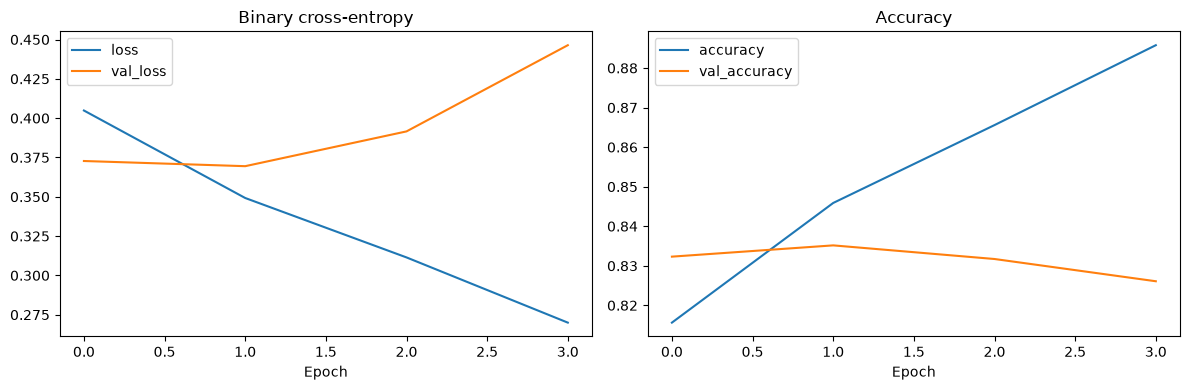

In [14]:
history_df = pd.DataFrame(history.history)
display(history_df.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
history_df[["loss", "val_loss"]].plot(ax=axes[0], title="Binary cross-entropy")
history_df[["accuracy", "val_accuracy"]].plot(ax=axes[1], title="Accuracy")
for ax in axes:
    ax.set_xlabel("Epoch")
plt.tight_layout()
plt.show()

## 5. Held-out test evaluation

The epoch 2 checkpoint was evaluated on the 154,131-example test split after model selection. Test accuracy was 83.48%, AUC was 0.9157, and binary cross-entropy loss was 0.3717. For positive sentiment, precision was 0.819, recall was 0.857, and F1 was 0.838. The confusion table below places actual labels in rows and predicted labels in columns; it shows 62,949 correctly classified negative tweets and 65,720 correctly classified positive tweets.

In [15]:
best_model = tf.keras.models.load_model(best_model_path)
test_metrics = best_model.evaluate(X["test"], y["test"], batch_size=BATCH_SIZE, return_dict=True)
display(pd.Series(test_metrics, name="test").round(4).to_frame())
positive_probability = best_model.predict(X["test"], batch_size=BATCH_SIZE, verbose=1).ravel()
predicted = (positive_probability >= 0.5).astype(np.int8)
confusion = pd.crosstab(
    pd.Series(y["test"], name="Actual").map({0: "negative", 1: "positive"}),
    pd.Series(predicted, name="Predicted").map({0: "negative", 1: "positive"}),
    dropna=False,
).reindex(index=["negative", "positive"], columns=["negative", "positive"], fill_value=0)
display(confusion)
precision = confusion.loc["positive", "positive"] / max(1, confusion["positive"].sum())
recall = confusion.loc["positive", "positive"] / max(1, confusion.loc["positive"].sum())
f1 = 2 * precision * recall / max(1e-12, precision + recall)
print(f"Positive-class precision: {precision:.3f}; recall: {recall:.3f}; F1: {f1:.3f}")

603/603 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step - accuracy: 0.8348 - auc: 0.9157 - loss: 0.3717


,test
accuracy,0.8348
auc,0.9157
loss,0.3717


603/603 ━━━━━━━━━━━━━━━━━━━━ 11s 18ms/step


Predicted,negative,positive
Actual,,
negative,62949,14479
positive,10983,65720


Positive-class precision: 0.819; recall: 0.857; F1: 0.838


## 6. Fine tuning and hyperparameter optimization

The baseline reached its lowest validation loss in epoch 2, while training accuracy continued to rise. This pattern suggests that generalization is a more useful tuning target than training accuracy. The experiment below compares three controlled changes against the original model: stronger dropout (`0.5`) to reduce reliance on individual features, fewer LSTM units (`32`) to reduce model capacity, and a lower learning rate (`3e-4`) to make weight updates smaller. Only one setting changes in each candidate, which makes the effect of each choice easier to interpret.

Each candidate uses the same training and validation splits, maximum of five epochs, early-stopping rule, and validation-loss checkpoint criterion as the baseline. The candidate with the lowest validation loss is selected; accuracy and AUC are also shown for context. This is a small manual hyperparameter search rather than an exhaustive search, and it does not establish that the selected settings are globally optimal. The cell trains three additional models and can take substantially longer than the earlier evaluation cells.


In [16]:
def build_bilstm(lstm_units=64, dropout_rate=0.3, learning_rate=1e-3):
    inputs = tf.keras.Input(shape=(MAX_LENGTH,), dtype="int32", name="token_ids")
    features = tf.keras.layers.Embedding(VOCAB_SIZE, EMBEDDING_DIM, mask_zero=True)(inputs)
    features = tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(lstm_units))(features)
    features = tf.keras.layers.Dropout(dropout_rate)(features)
    outputs = tf.keras.layers.Dense(1, activation="sigmoid", name="positive_probability")(features)
    candidate = tf.keras.Model(inputs, outputs)
    candidate.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[tf.keras.metrics.BinaryAccuracy(name="accuracy"), tf.keras.metrics.AUC(name="auc")],
    )
    return candidate


tuning_candidates = {
    "stronger_dropout": {"lstm_units": 64, "dropout_rate": 0.5, "learning_rate": 1e-3},
    "smaller_lstm": {"lstm_units": 32, "dropout_rate": 0.3, "learning_rate": 1e-3},
    "lower_learning_rate": {"lstm_units": 64, "dropout_rate": 0.3, "learning_rate": 3e-4},
}

baseline_epoch = int(np.argmin(history.history["val_loss"]))
tuning_results = [{
    "candidate": "baseline",
    "lstm_units": LSTM_UNITS,
    "dropout_rate": 0.3,
    "learning_rate": 1e-3,
    "best_epoch": baseline_epoch + 1,
    "val_loss": history.history["val_loss"][baseline_epoch],
    "val_accuracy": history.history["val_accuracy"][baseline_epoch],
    "val_auc": history.history["val_auc"][baseline_epoch],
    "checkpoint": str(best_model_path),
}]

for trial_number, (name, parameters) in enumerate(tuning_candidates.items(), start=1):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    candidate = build_bilstm(**parameters)
    checkpoint = MODEL_DIR / f"bilstm_{name}.keras"
    candidate_history = candidate.fit(
        X["train"], y["train"],
        validation_data=(X["validation"], y["validation"]),
        batch_size=BATCH_SIZE,
        epochs=EPOCHS,
        callbacks=[
            tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True),
            tf.keras.callbacks.ModelCheckpoint(checkpoint, monitor="val_loss", save_best_only=True),
        ],
        verbose=1,
    )
    best_epoch = int(np.argmin(candidate_history.history["val_loss"]))
    tuning_results.append({
        "candidate": name,
        **parameters,
        "best_epoch": best_epoch + 1,
        "val_loss": candidate_history.history["val_loss"][best_epoch],
        "val_accuracy": candidate_history.history["val_accuracy"][best_epoch],
        "val_auc": candidate_history.history["val_auc"][best_epoch],
        "checkpoint": str(checkpoint),
    })
    del candidate

tuning_df = pd.DataFrame(tuning_results).sort_values("val_loss").reset_index(drop=True)
display(tuning_df.drop(columns="checkpoint").round(4))
selected_candidate = tuning_df.iloc[0]
print(f"Selected by validation loss: {selected_candidate['candidate']}")
print(f"Checkpoint: {selected_candidate['checkpoint']}")


Epoch 1/5
4817/4817 ━━━━━━━━━━━━━━━━━━━━ 652s 135ms/step - accuracy: 0.8146 - auc: 0.8958 - loss: 0.4074 - val_accuracy: 0.8317 - val_auc: 0.9135 - val_loss: 0.3742
Epoch 2/5
4817/4817 ━━━━━━━━━━━━━━━━━━━━ 382s 79ms/step - accuracy: 0.8440 - auc: 0.9229 - loss: 0.3532 - val_accuracy: 0.8355 - val_auc: 0.9163 - val_loss: 0.3707
Epoch 3/5
4817/4817 ━━━━━━━━━━━━━━━━━━━━ 381s 79ms/step - accuracy: 0.8628 - auc: 0.9381 - loss: 0.3175 - val_accuracy: 0.8323 - val_auc: 0.9108 - val_loss: 0.3917
Epoch 4/5
4817/4817 ━━━━━━━━━━━━━━━━━━━━ 398s 83ms/step - accuracy: 0.8819 - auc: 0.9526 - loss: 0.2784 - val_accuracy: 0.8278 - val_auc: 0.9018 - val_loss: 0.4363
Epoch 1/5
4817/4817 ━━━━━━━━━━━━━━━━━━━━ 228s 47ms/step - accuracy: 0.8146 - auc: 0.8960 - loss: 0.4070 - val_accuracy: 0.8311 - val_auc: 0.9132 - val_loss: 0.3752
Epoch 2/5
4817/4817 ━━━━━━━━━━━━━━━━━━━━ 213s 44ms/step - accuracy: 0.8446 - auc: 0.9234 - loss: 0.3522 - val_accuracy: 0.8347 - val_auc: 0.9156 - val_loss: 0.3716
Epoch 3/5
4817/

,candidate,lstm_units,dropout_rate,learning_rate,best_epoch,val_loss,val_accuracy,val_auc
0,baseline,64,0.3,0.0010,2,0.3695,0.8352,0.9167
1,stronger_dropout,64,0.5,0.0010,2,0.3707,0.8355,0.9163
2,smaller_lstm,32,0.3,0.0010,2,0.3716,0.8347,0.9156
3,lower_learning_rate,64,0.3,0.0003,2,0.3811,0.8290,0.9103


Selected by validation loss: baseline
Checkpoint: models/bilstm_sentiment.keras


## 7. Visualization and Critical Analysis

Matplotlib is used to summarize the model architecture, learning curves, test-set predictions, and hyperparameter comparison. The architecture diagram shows the flow of information through the selected baseline model. The performance figures separate the three roles of the data: training curves describe fitting, validation results support model selection, and the confusion matrix describes the baseline checkpoint's held-out test predictions.


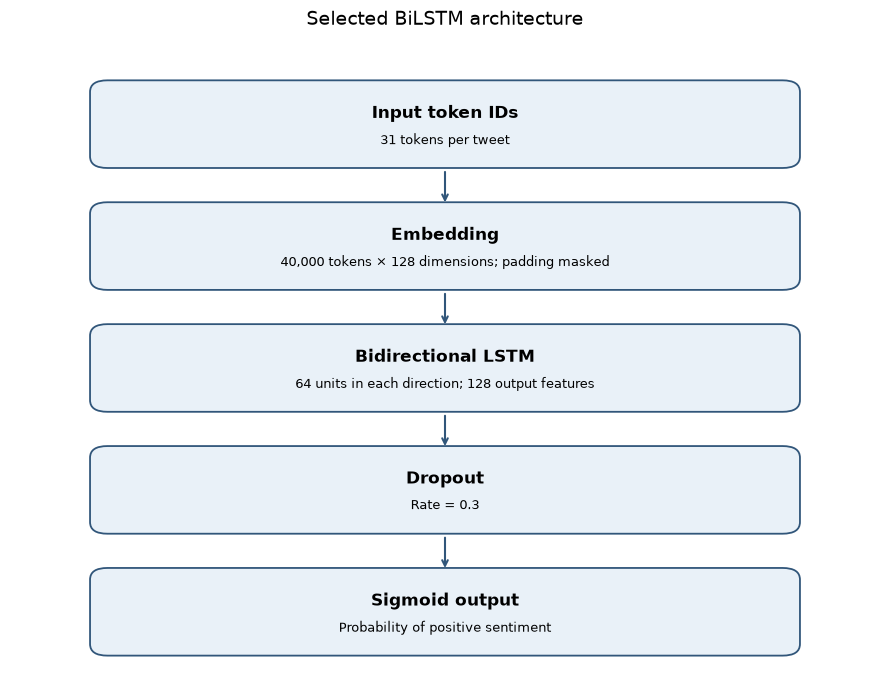

In [17]:
from matplotlib.patches import FancyBboxPatch

architecture = [
    ("Input token IDs", f"31 tokens per tweet"),
    ("Embedding", f"{VOCAB_SIZE:,} tokens × {EMBEDDING_DIM} dimensions; padding masked"),
    ("Bidirectional LSTM", f"{LSTM_UNITS} units in each direction; 128 output features"),
    ("Dropout", "Rate = 0.3"),
    ("Sigmoid output", "Probability of positive sentiment"),
]

fig, ax = plt.subplots(figsize=(9, 7))
ax.set_xlim(0, 10)
ax.set_ylim(0, 11)
ax.axis("off")
for index, (layer, detail) in enumerate(architecture):
    y_position = 9.6 - index * 2.1
    box = FancyBboxPatch(
        (1, y_position - 0.7), 8, 1.35,
        boxstyle="round,pad=0.08,rounding_size=0.2",
        linewidth=1.3, edgecolor="#31567a", facecolor="#e9f1f8",
    )
    ax.add_patch(box)
    ax.text(5, y_position + 0.16, layer, ha="center", va="center", fontsize=12, weight="bold")
    ax.text(5, y_position - 0.3, detail, ha="center", va="center", fontsize=9)
    if index < len(architecture) - 1:
        ax.annotate("", xy=(5, y_position - 1.42), xytext=(5, y_position - 0.8),
                    arrowprops={"arrowstyle": "->", "linewidth": 1.5, "color": "#31567a"})
ax.set_title("Selected BiLSTM architecture", fontsize=14, pad=12)
plt.tight_layout()
plt.show()


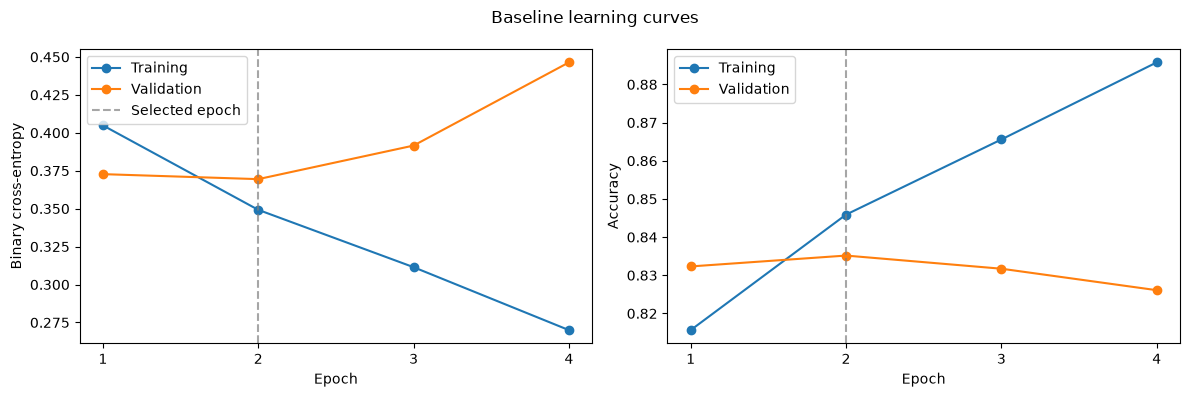

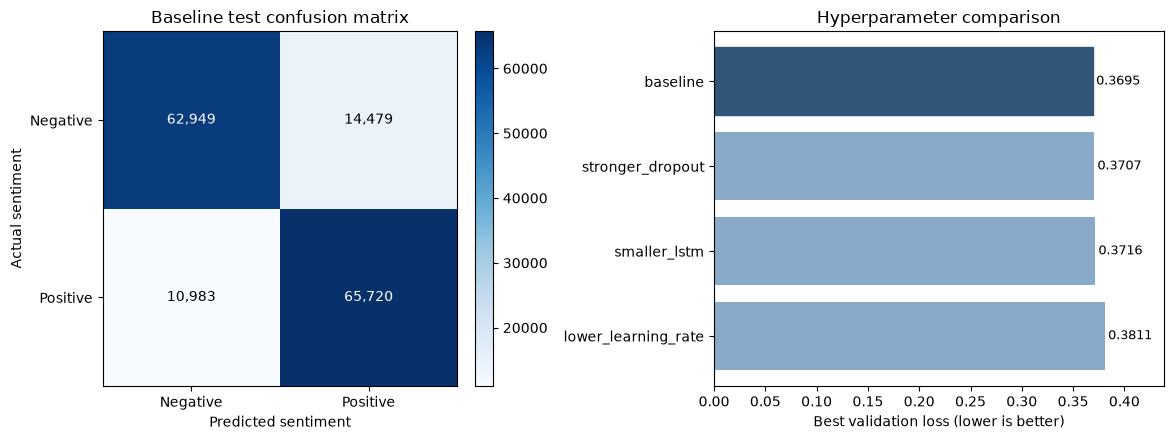

In [18]:
best_epoch_number = int(np.argmin(history_df["val_loss"])) + 1
epochs = np.arange(1, len(history_df) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, label in zip(axes, ["loss", "accuracy"], ["Binary cross-entropy", "Accuracy"]):
    ax.plot(epochs, history_df[metric], marker="o", label="Training")
    ax.plot(epochs, history_df[f"val_{metric}"], marker="o", label="Validation")
    ax.axvline(best_epoch_number, color="gray", linestyle="--", alpha=0.7,
               label="Selected epoch" if metric == "loss" else None)
    ax.set(xlabel="Epoch", ylabel=label, xticks=epochs)
    ax.legend()
fig.suptitle("Baseline learning curves")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
matrix = confusion.to_numpy()
image = axes[0].imshow(matrix, cmap="Blues")
axes[0].set(xticks=[0, 1], yticks=[0, 1],
            xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"],
            xlabel="Predicted sentiment", ylabel="Actual sentiment",
            title="Baseline test confusion matrix")
for row in range(2):
    for column in range(2):
        axes[0].text(column, row, f"{matrix[row, column]:,}", ha="center", va="center",
                     color="white" if matrix[row, column] > matrix.max() / 2 else "black")
fig.colorbar(image, ax=axes[0], fraction=0.046, pad=0.04)

comparison = tuning_df.sort_values("val_loss")
bars = axes[1].barh(comparison["candidate"], comparison["val_loss"], color="#88a9c7")
bars[0].set_color("#31567a")
axes[1].invert_yaxis()
axes[1].set(xlabel="Best validation loss (lower is better)",
            title="Hyperparameter comparison")
axes[1].set_xlim(0, max(comparison["val_loss"]) * 1.15)
for bar, value in zip(bars, comparison["val_loss"]):
    axes[1].text(value + 0.003, bar.get_y() + bar.get_height() / 2,
                 f"{value:.4f}", va="center", fontsize=9)
plt.tight_layout()
plt.show()


### Critical analysis of model performance

The baseline's training accuracy rose from 81.56% to 88.58%, but validation accuracy peaked at 83.52% in epoch 2 and then declined to 82.61%. Validation loss also rose from its minimum of 0.3695 in epoch 2 to 0.4464 in epoch 4. This divergence is consistent with overfitting: additional training improved performance on examples seen during fitting but reduced generalization to the validation split. Early stopping and checkpointing therefore selected epoch 2 rather than the final epoch.

The selected baseline checkpoint achieved 83.48% accuracy, 0.9157 AUC, and 0.838 positive-class F1 on 154,131 held-out test tweets. The confusion matrix contains 62,949 true negatives, 65,720 true positives, 14,479 false positives, and 10,983 false negatives. Positive recall (85.7%) exceeds positive precision (81.9%), so the model identifies most positive tweets but also labels a noticeable number of negative tweets as positive. Accuracy alone would hide that difference between error types.

The manual hyperparameter search did not improve the selected validation criterion. The baseline had the lowest validation loss (0.3695), followed by stronger dropout (0.3707), a smaller LSTM (0.3716), and a lower learning rate (0.3811). Stronger dropout increased validation accuracy slightly, from 83.52% to 83.55%, but its loss and AUC were worse; the accuracy difference is only 0.03 percentage points. These results support retaining the original checkpoint among the four configurations tested. They do not establish that further tuning would be ineffective.

The evaluation also has limits. The split is random within a single dataset, so it does not test performance on tweets collected at another time or from another source. Sentiment labels can be ambiguous for short or context-dependent text, as the duplicate-label analysis in notebook 01 showed. The original test set was viewed before the tuning experiments; it should not be used repeatedly to select a tuned model. The reported test metrics remain specific to the original baseline checkpoint.
